# MILES-GUESS Regression Example Notebook (PyTorch)

John Schreck, David John Gagne, Charlie Becker, Gabrielle Gantos, Dhamma Kimpara, Thomas Martin

This is the authors' original Cabauw example, extended with held-out evaluation. It uses the **bundled original surface-layer observations**, the same four inputs and friction-velocity target, the YAML's five 1057-unit hidden layers and dropout rates, batch size 128, Adam at 0.001, and **one pass through training data for each model**, as in the original notebook. There is no replacement dataset, shortened training run, or hyperparameter search.

Portability changes: paths work from the repository or notebook directory; CPU is the default; the configuration seed also fixes initialization and shuffling. The original code groups both splits by **year** (despite its old text saying day); that behavior is retained. Preprocessing is fitted on training data only. Test data are evaluated after both models have finished training. The deterministic L1 and evidential Lipschitz-MSE objectives are retained. The modern library converts target variances using the squared inverse scaling factor; the old `training_var` attribute is unnecessary.

Install with `python -m pip install -e ".[torch,notebooks]"` after installing your intended CPU PyTorch build. The full original model can take several minutes on a CPU. The results demonstrate this original single-pass setup; they are not a claim of a tuned model or a reproduction of the paper's full experiment.


In [1]:
from pathlib import Path
from collections import defaultdict
import json
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import MinMaxScaler, RobustScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from mlguess.torch.models import DNN, seed_everything
from mlguess.evaluation import evaluate_nig
REPO_ROOT = next((path for path in (Path.cwd(), Path.cwd().parent)
                  if (path / "config").is_dir() and (path / "mlguess").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Run this notebook from the repository root or its notebooks directory.")


## Config File

#### Load the config file

In [2]:
config = REPO_ROOT / "config/evidential_regression_torch.yml"
with config.open() as cf:
    conf = yaml.safe_load(cf)
seed_everything(conf["seed"])


## Data

#### Load Surface Layer data from the repo

In [3]:
DATA_PATH = REPO_ROOT / "data/sample_cabauw_surface_layer.csv"
data = pd.read_csv(DATA_PATH)
data["day"] = data["Time"].apply(lambda x: str(x).split(" ")[0])
data["year"] = data["Time"].apply(lambda x: str(x).split("-")[0])
print(f"Original Cabauw sample: {len(data):,} observations from {DATA_PATH.name}")


Original Cabauw sample: 72,197 observations from sample_cabauw_surface_layer.csv


#### Train–validation–test splits

Retain the authors' two `GroupShuffleSplit` calls with seed 1000 and **year** groups: 90% of groups first enter the development partition; 88.5% of its groups then enter training. Thus the proportions of observations need not equal these proportions of groups. The held-out years stay disjoint. The validation split is available for future model development; this original one-pass demonstration does not select checkpoints or tune hyperparameters.


In [4]:
data_seed = 0
flat_seed = 1000


In [5]:
# Preserve the original year-group splits and seeds.
gsp = GroupShuffleSplit(n_splits=1, random_state=flat_seed, train_size=0.9)
train_index, test_index = next(gsp.split(data, groups=data["year"]))
train_data, test_data = data.iloc[train_index].copy(), data.iloc[test_index].copy()
gsp = GroupShuffleSplit(n_splits=1, random_state=flat_seed, train_size=0.885)
train_index, valid_index = list(gsp.split(train_data, groups=train_data["year"]))[data_seed]
train_data, valid_data = train_data.iloc[train_index].copy(), train_data.iloc[valid_index].copy()
for first, second in ((train_data, valid_data), (train_data, test_data), (valid_data, test_data)):
    assert set(first["year"]).isdisjoint(second["year"])
display(pd.DataFrame({name: {"observations": len(frame), "years": ", ".join(sorted(frame["year"].unique()))}
                      for name, frame in {"train": train_data, "validation": valid_data, "test": test_data}.items()}).T)


,observations,years
train,55007,"2003, 2004, 2007, 2009, 2010, 2011, 2012, 2013..."
validation,6598,"2006, 2017"
test,10592,"2005, 2008"


#### Data Scaling

In [6]:
input_cols = conf["data"]["input_cols"]
output_cols = ["friction_velocity:surface:m_s-1"]  # Original notebook target.


In [7]:
x_scaler, y_scaler = RobustScaler(), MinMaxScaler((0, 1))
x_train = x_scaler.fit_transform(train_data[input_cols])
x_valid = x_scaler.transform(valid_data[input_cols])
x_test = x_scaler.transform(test_data[input_cols])

y_train = y_scaler.fit_transform(train_data[output_cols])
y_valid = y_scaler.transform(valid_data[output_cols])
y_test = y_scaler.transform(test_data[output_cols])

In [8]:
X = torch.FloatTensor(x_train)
y = torch.FloatTensor(y_train)

batch_size = 128

# Create dataset and dataloader
dataset = TensorDataset(X, y)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

### 1. Deterministic multi-layer perceptron (MLP) to predict some quantity

#### Train the model

In [9]:
conf["model"]["lng"] = False
device = torch.device("cpu")  # Set "cuda" explicitly if a CUDA build and GPU are available.


In [10]:
model = DNN(**conf["model"]).to(device)

In [11]:
model

Out[11]: 
DNN(
  (fcn): Sequential(
    (0): Linear(in_features=4, out_features=1057, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Dropout(p=0.263, inplace=False)
    (3): Linear(in_features=1057, out_features=1057, bias=True)
    (4): LeakyReLU(negative_slope=0.01)
    (5): Dropout(p=0.263, inplace=False)
    (6): Linear(in_features=1057, out_features=1057, bias=True)
    (7): LeakyReLU(negative_slope=0.01)
    (8): Dropout(p=0.263, inplace=False)
    (9): Linear(in_features=1057, out_features=1057, bias=True)
    (10): LeakyReLU(negative_slope=0.01)
    (11): Dropout(p=0.263, inplace=False)
    (12): Linear(in_features=1057, out_features=1057, bias=True)
    (13): LeakyReLU(negative_slope=0.01)
    (14): Dropout(p=0.263, inplace=False)
    (15): Linear(in_features=1057, out_features=1, bias=True)
  )
)


In [12]:
results_dict = defaultdict(list)
criterion = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
model.train()
for x, y in dataloader:  # One full training pass, unchanged from the authors' example.
    x, y = x.to(device), y.to(device)
    y_pred = model(x)
    loss = criterion(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    results_dict["batch_loss"].append(loss.item())
deterministic_model = model
point_training_loss = results_dict["batch_loss"]
print(f"Deterministic model: {len(point_training_loss)} training batches; last L1 loss {loss.item():.6g}")


Deterministic model: 430 training batches; last L1 loss 0.0296112


### Now lets use the evidential regressor

In [13]:
conf["model"]["lng"] = True

In [14]:
model = DNN(**conf["model"]).to(device)

In [15]:
model

Out[15]: 
DNN(
  (fcn): Sequential(
    (0): Linear(in_features=4, out_features=1057, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Dropout(p=0.263, inplace=False)
    (3): Linear(in_features=1057, out_features=1057, bias=True)
    (4): LeakyReLU(negative_slope=0.01)
    (5): Dropout(p=0.263, inplace=False)
    (6): Linear(in_features=1057, out_features=1057, bias=True)
    (7): LeakyReLU(negative_slope=0.01)
    (8): Dropout(p=0.263, inplace=False)
    (9): Linear(in_features=1057, out_features=1057, bias=True)
    (10): LeakyReLU(negative_slope=0.01)
    (11): Dropout(p=0.263, inplace=False)
    (12): Linear(in_features=1057, out_features=1057, bias=True)
    (13): LeakyReLU(negative_slope=0.01)
    (14): Dropout(p=0.263, inplace=False)
    (15): LinearNormalGamma(
      (linear): Linear(in_features=1057, out_features=4, bias=True)
    )
  )
)


### Evidential training

The original NIG architecture and `LipschitzMSELoss` settings are retained. The model provides the NIG parameters directly; the modern uncertainty implementation uses the fitted target scaler for physical units and does not require the old `training_var` attribute.


In [16]:
# Training-target scaling is retained in y_scaler; no extra variance multiplier is required.


In [17]:
from mlguess.torch.regression_losses import LipschitzMSELoss

In [18]:
results_dict = defaultdict(list)
criterion = LipschitzMSELoss(**conf["train_loss"])
optimizer = optim.Adam(model.parameters(), lr=0.001)
model.train()
for x, y in dataloader:  # The same original one-pass training limit.
    x, y = x.to(device), y.to(device)
    gamma, nu, alpha, beta = model(x)
    loss = criterion(gamma, nu, alpha, beta, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    results_dict["batch_loss"].append(loss.item())
evidential_model = model
evidential_training_loss = results_dict["batch_loss"]
print(f"Evidential model: {len(evidential_training_loss)} training batches; last objective {loss.item():.6g}")


Evidential model: 430 training batches; last objective -1.43546


## Held-out test evaluation in physical units

Freeze both trained models before using the test set. Dropout is disabled during these single-model evaluations. MAE and RMSE are in m s⁻¹; NLL is the marginal Student-t negative log density in those same units. The deterministic model has no predicted variance, so its NLL and interval coverage are not defined. For the evidential model, aleatoric and epistemic variances add to predictive variance. Central intervals come from its exact NIG predictive **Student-t** distribution, rather than a Gaussian approximation.

The two training curves use different loss functions and are shown separately. Test metrics are computed over every held-out observation, without selecting a favorable subset.


In [19]:
# Batched inference keeps evaluation memory bounded without changing training settings.
def batched_forward(trained_model, features, batch_size=1024):
    trained_model.eval()
    chunks = []
    with torch.inference_mode():
        for start in range(0, len(features), batch_size):
            inputs = torch.as_tensor(features[start:start + batch_size], dtype=torch.float32, device=device)
            output = trained_model(inputs)
            chunks.append(tuple(value.cpu().numpy() for value in output) if isinstance(output, tuple)
                          else output.cpu().numpy())
    if isinstance(chunks[0], tuple):
        return tuple(np.concatenate([chunk[index] for chunk in chunks]) for index in range(4))
    return np.concatenate(chunks)

truth = test_data[output_cols].to_numpy()
point_mean = y_scaler.inverse_transform(batched_forward(deterministic_model, x_test))
nig_parameters = batched_forward(evidential_model, x_test)
evidential_test = evaluate_nig(truth, nig_parameters, y_scaler=y_scaler,
                               interval_levels=(0.5, 0.8, 0.9, 0.95))
point_metrics = {"mae": mean_absolute_error(truth, point_mean),
                 "rmse": np.sqrt(mean_squared_error(truth, point_mean)),
                 "r2": r2_score(truth, point_mean), "nll": np.nan}
test_metrics = pd.DataFrame([point_metrics, evidential_test["metrics"].iloc[0].to_dict()],
                            index=["Deterministic L1", "Evidential Lipschitz-MSE"])
display(test_metrics)
display(evidential_test["coverage"])
assert np.allclose(evidential_test["total"], evidential_test["aleatoric"] + evidential_test["epistemic"])


,mae,rmse,r2,nll
Deterministic L1,0.038076,0.054568,0.883114,NaN
Evidential Lipschitz-MSE,0.039949,0.055647,0.878446,-1.506595


,target,nominal,observed,mean_width
0,0,0.50,0.604702,0.079153
1,0,0.80,0.927398,0.177391
2,0,0.90,0.973187,0.266634
3,0,0.95,0.991125,0.379695


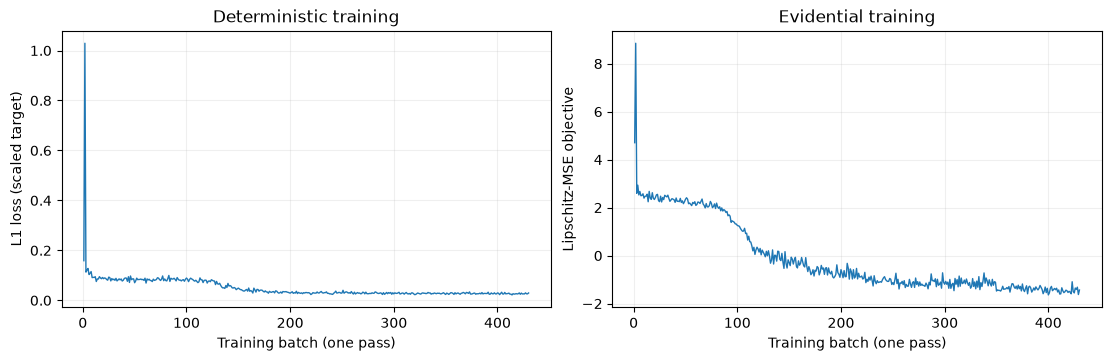

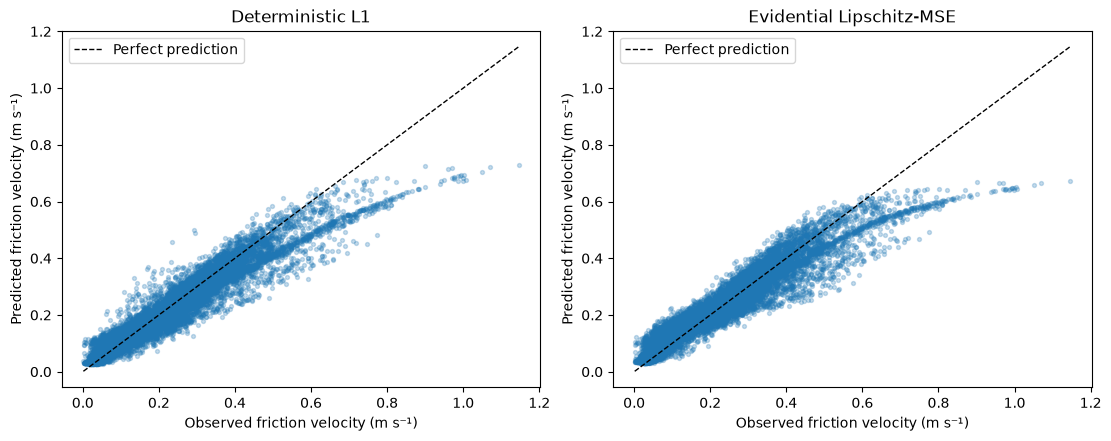

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
for ax, values, title, ylabel in zip(axes, [point_training_loss, evidential_training_loss],
                                    ["Deterministic training", "Evidential training"],
                                    ["L1 loss (scaled target)", "Lipschitz-MSE objective"]):
    ax.plot(np.arange(1, len(values) + 1), values, lw=1)
    ax.set(title=title, xlabel="Training batch (one pass)", ylabel=ylabel)
    ax.grid(alpha=0.2)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), constrained_layout=True)
for ax, prediction, label in zip(axes, [point_mean, evidential_test["mean"]], test_metrics.index):
    bounds = [min(truth.min(), prediction.min()), max(truth.max(), prediction.max())]
    ax.scatter(truth[:, 0], prediction[:, 0], s=8, alpha=0.25, rasterized=True)
    ax.plot(bounds, bounds, "k--", lw=1, label="Perfect prediction")
    ax.set(title=label, xlabel="Observed friction velocity (m s⁻¹)", ylabel="Predicted friction velocity (m s⁻¹)")
    ax.legend()
plt.show()


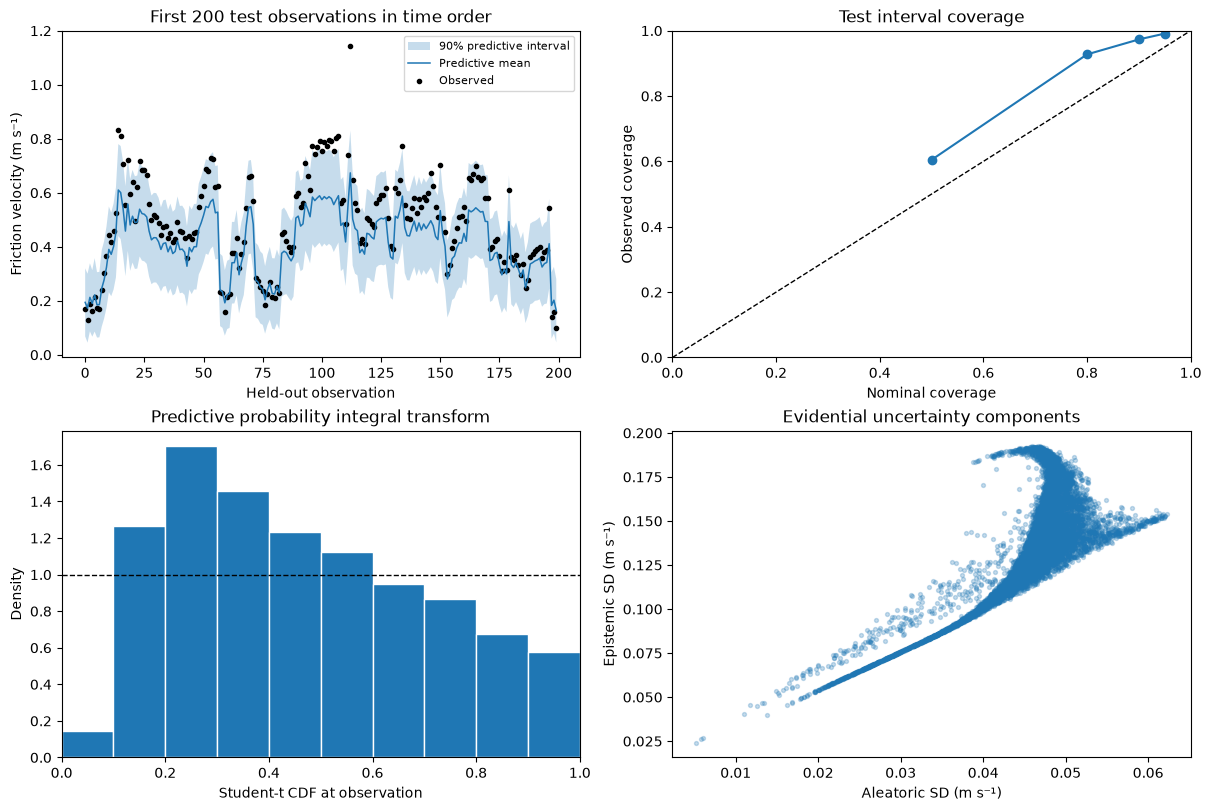

In [21]:
# A fixed chronological excerpt is for readability; metrics above use the whole test set.
selected = np.argsort(pd.to_datetime(test_data["Time"]).to_numpy(), kind="stable")[:200]
lower, upper = evidential_test["intervals"][0.9]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
ax = axes[0, 0]
ax.fill_between(np.arange(len(selected)), lower[selected, 0], upper[selected, 0], alpha=0.25,
                label="90% predictive interval")
ax.plot(evidential_test["mean"][selected, 0], lw=1.1, label="Predictive mean")
ax.scatter(np.arange(len(selected)), truth[selected, 0], s=9, c="black", label="Observed")
ax.set(title="First 200 test observations in time order", xlabel="Held-out observation", ylabel="Friction velocity (m s⁻¹)")
ax.legend(fontsize=8)
coverage = evidential_test["coverage"]
axes[0, 1].plot([0, 1], [0, 1], "k--", lw=1)
axes[0, 1].plot(coverage["nominal"], coverage["observed"], "o-")
axes[0, 1].set(title="Test interval coverage", xlabel="Nominal coverage", ylabel="Observed coverage", xlim=(0, 1), ylim=(0, 1))
axes[1, 0].hist(evidential_test["pit"][:, 0], bins=np.linspace(0, 1, 11), density=True, edgecolor="white")
axes[1, 0].axhline(1, color="black", linestyle="--", lw=1)
axes[1, 0].set(title="Predictive probability integral transform", xlabel="Student-t CDF at observation", ylabel="Density", xlim=(0, 1))
axes[1, 1].scatter(np.sqrt(evidential_test["aleatoric"][:, 0]), np.sqrt(evidential_test["epistemic"][:, 0]),
                    s=8, alpha=0.25, rasterized=True)
axes[1, 1].set(title="Evidential uncertainty components", xlabel="Aleatoric SD (m s⁻¹)", ylabel="Epistemic SD (m s⁻¹)")
plt.show()


In [22]:
OUTPUT_DIR = REPO_ROOT / "outputs/authors_regression_torch"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
test_metrics.to_csv(OUTPUT_DIR / "test_metrics.csv")
evidential_test["coverage"].to_csv(OUTPUT_DIR / "test_interval_coverage.csv", index=False)
predictions = pd.DataFrame({"source_row": test_data.index, "time": test_data["Time"].to_numpy(),
    "observed": truth[:, 0], "deterministic_mean": point_mean[:, 0],
    "evidential_mean": evidential_test["mean"][:, 0],
    "aleatoric_variance": evidential_test["aleatoric"][:, 0],
    "epistemic_variance": evidential_test["epistemic"][:, 0],
    "total_variance": evidential_test["total"][:, 0],
    "predictive_lower_90": lower[:, 0], "predictive_upper_90": upper[:, 0]})
predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
print(f"Saved full held-out predictions and metrics to {OUTPUT_DIR}")


Saved full held-out predictions and metrics to /workspace/scratch/d7d34632ac75/miles-guess/outputs/authors_regression_torch


These plots assess the original one-pass models as trained. Coverage and PIT diagnose the predictive distribution; they do not by themselves establish calibrated epistemic uncertainty or out-of-distribution detection. Any future tuning should use training/validation data, followed by evaluation on a fresh untouched test set.


### Questions? Email John Schreck (schreck@ucar.edu)